# Does the perturbation survive the real pipeline, and does it depend on the prompt?

Uses the perturbation **v** trained in notebook 01 (no retraining). Two questions:

**A. Prompt dependence.** v was built without any text. Does it still break the answers for other prompts, including a closed yes/no question? (Same setup as in training: v added after preprocessing.)

**B. Real pipeline.** During training, v was added *after* SmolVLM's preprocessing. Here it is added to the image itself, the image is saved as 8-bit (uint8), and the **standard processor** prepares it, as a real user would:
- **B1:** processor with image splitting **off** (one 512 × 512 tile, as in training);
- **B2:** processor with its **default** settings (image splitting on), on a smaller subset because it is slower.

Random noise of the same budget is the baseline throughout.

**Before running:** T4 GPU, then `Run all`. Rough estimate: 10–15 min.

**Outputs:** the prompt-dependence results (section 5), the real-pipeline results (section 6) and example answers (section 7), saved to `pipeline_prompts_results.json` together with three figures.

## 1. Configuration

In [1]:
MODEL_ID   = "HuggingFaceTB/SmolVLM-256M-Instruct"
IMG_SIZE   = 512
N_BUILD    = 500                 # skipped: these images built v (same split as in training)
N_PROMPT   = 100                 # eval images for part A
N_PIPE     = 200                 # eval images for part B1
N_SPLIT    = 50                  # eval images for part B2 (image splitting is slower)
NORM_XI    = 10/255
V_PATH     = "/content/drive/MyDrive/uap_smolvlm/uap_smolvlm256m_linf10.npy"
OUT_DIR    = "/content/drive/MyDrive/uap_smolvlm"
CAPTION_SIM_CHANGED = 0.5
MAX_NEW_TOKENS = 40
PROMPTS = {
    "describe (training)": "Describe this image in one sentence.",
    "what is in it":     "What is in this image?",
    "main object":       "What is the main object in this picture? Answer in a few words.",
    "animal yes/no":     "Is there an animal in this image? Answer yes or no.",
}
SEED = 0

## 2. Setup, data (eval images only) and model

In [2]:
!pip -q install "transformers>=4.50" sentence-transformers
import time, json, glob, random, tarfile
from pathlib import Path
import numpy as np, torch, torch.nn.functional as F
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")
DEVICE = "cuda"; assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = Path(OUT_DIR)

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR = DATA_DIR / "imagenetv2-matched-frequency.tar.gz"
if not list(DATA_DIR.glob("imagenetv2-*/")):
    !wget -q --show-progress -O {TAR} https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz
    with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)
    TAR.unlink()
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
perm = np.random.RandomState(SEED).permutation(len(FILES))
n_eval = max(N_PROMPT, N_PIPE, N_SPLIT)
files_eval = [FILES[i] for i in perm[N_BUILD:N_BUILD + n_eval]]     # same held-out images as in training
PREPROC = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE), transforms.PILToTensor()])
E_u8 = torch.stack([PREPROC(Image.open(f).convert("RGB")) for f in tqdm(files_eval, desc="decoding")])

from transformers import AutoProcessor, AutoModelForImageTextToText
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to(DEVICE).eval()
VIS = model.model.vision_model
ip = processor.image_processor
MEAN = torch.tensor(ip.image_mean, device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor(ip.image_std,  device=DEVICE).view(1, 3, 1, 1)

v = torch.from_numpy(np.load(V_PATH)).to(DEVICE).float()
torch.manual_seed(SEED)
v_rand = NORM_XI * torch.sign(torch.randn_like(v))
print("Loaded v:", tuple(v.shape), "||v||_inf =", round(v.abs().max().item() * 255, 2), "/255")

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
def text_sim(a, b):
    ea = st.encode(a, convert_to_tensor=True, normalize_embeddings=True)
    eb = st.encode(b, convert_to_tensor=True, normalize_embeddings=True)
    return (ea * eb).sum(-1).cpu()
def yesno(s):
    w = s.strip().lower().lstrip("*\"' ").split()
    return w[0].strip(".,!") if w else ""

Mounted at /content/drive
/content/data/image 100%[===================>]   1.18G  74.9MB/s    in 16s     


/tmp/ipykernel_1926/1318672904.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(TAR, "r:*") as t: t.extractall(DATA_DIR)


decoding:   0%|          | 0/200 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

... (22 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 3. Generation helpers

In [3]:
def chat(prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return processor.apply_chat_template(msgs, add_generation_prompt=True)

def to01(u8): return u8.to(DEVICE).float().div(255)
def norm(x01): return (x01 - MEAN) / STD

@torch.no_grad()
def gen_tensor(x01, prompt, bs=16):
    # Training path: our own pixel_values (perturbation added after preprocessing)
    dummy = Image.fromarray(np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8))
    base = processor(text=chat(prompt), images=[dummy], do_image_splitting=False, return_tensors="pt")
    outs = []
    for i in range(0, len(x01), bs):
        xb = x01[i:i+bs]; B = len(xb)
        inp = {k: t.repeat(B, *[1] * (t.dim() - 1)).to(DEVICE) for k, t in base.items() if k != "pixel_values"}
        inp["pixel_values"] = norm(xb).unsqueeze(1)
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

def to_pil_u8(u8, pert=None):
    # Real-pipeline path: add v in pixel space, then save as an 8-bit image
    x = u8.float()
    if pert is not None:
        x = x + pert[0].cpu() * 255
    x = x.round().clamp(0, 255).to(torch.uint8)
    return Image.fromarray(x.permute(1, 2, 0).numpy())

@torch.no_grad()
def gen_pipeline(u8_batch, prompt, pert, split, bs=8):
    outs, tiles = [], None
    for i in range(0, len(u8_batch), bs):
        pils = [to_pil_u8(u, pert) for u in u8_batch[i:i+bs]]
        inp = processor(text=[chat(prompt)] * len(pils), images=[[p] for p in pils],
                        do_image_splitting=split, return_tensors="pt", padding=True).to(DEVICE)
        tiles = inp["pixel_values"].shape[1]
        g = model.generate(**inp, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)
        outs += processor.batch_decode(g[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs], tiles

@torch.no_grad()
def token_cos_pipeline(u8_batch, pert, split):
    # Visual-token cosine between clean and perturbed images, both through the standard processor
    cs = []
    for u in u8_batch:
        pv = []
        for p in (None, pert):
            px = processor.image_processor(images=[[to_pil_u8(u, p)]], do_image_splitting=split, return_tensors="pt")["pixel_values"][0]
            pv.append(px.to(DEVICE))
        z0, z1 = VIS(pixel_values=pv[0]).last_hidden_state, VIS(pixel_values=pv[1]).last_hidden_state
        cs.append(F.cosine_similarity(z0, z1, dim=-1).mean().item())
    return float(np.mean(cs))

## 4. Run all conditions

In [4]:
R = {"A_prompts": {}, "B_pipeline": {}}
EX = {}
t0 = time.time()

# ---- A. prompt dependence (training path) ----
xA = to01(E_u8[:N_PROMPT])
for pname, prompt in PROMPTS.items():
    c0 = gen_tensor(xA, prompt)
    row = {}
    for cond, pert in [("universal v", v), ("random ±ξ", v_rand)]:
        c1 = gen_tensor((xA + pert).clamp(0, 1), prompt)
        if pname == "animal yes/no":
            a0, a1 = [yesno(s) for s in c0], [yesno(s) for s in c1]
            row[cond] = {"answer_flipped": float(np.mean([p != q for p, q in zip(a0, a1)])),
                         "valid_yes_no_after": float(np.mean([a in ("yes", "no") for a in a1]))}
        else:
            sim = text_sim(c0, c1)
            row[cond] = {"mean_sim": sim.mean().item(), "changed": (sim < CAPTION_SIM_CHANGED).float().mean().item()}
        EX[f"A|{pname}|{cond}"] = list(zip(c0[:3], c1[:3]))
    R["A_prompts"][pname] = row
    print(f"A done: {pname} ({(time.time()-t0)/60:.1f} min)")

# ---- B. real pipeline: v in the 8-bit image, standard processor ----
P0 = PROMPTS["describe (training)"]
for label, split, n in [("B1 splitting off", False, N_PIPE), ("B2 splitting on (default)", True, N_SPLIT)]:
    u8s = E_u8[:n]
    c0, tiles = gen_pipeline(u8s, P0, None, split)
    row = {"n_images": n, "tiles_per_image": int(tiles)}
    for cond, pert in [("universal v", v), ("random ±ξ", v_rand)]:
        c1, _ = gen_pipeline(u8s, P0, pert, split)
        sim = text_sim(c0, c1)
        row[cond] = {"mean_sim": sim.mean().item(), "changed": (sim < CAPTION_SIM_CHANGED).float().mean().item(),
                     "token_cos": token_cos_pipeline(u8s[:min(n, 50)], pert, split)}
        EX[f"B|{label}|{cond}"] = list(zip(c0[:3], c1[:3]))
    R["B_pipeline"][label] = row
    print(f"{label} done ({(time.time()-t0)/60:.1f} min)")

A done: describe (training) (1.1 min)
A done: what is in it (2.3 min)
A done: main object (3.0 min)
A done: animal yes/no (3.6 min)
B1 splitting off done (6.6 min)
B2 splitting on (default) done (14.8 min)


## 5. Part A results: does v depend on the prompt?

In [5]:
print(f"{N_PROMPT} held-out images, v added after preprocessing (as in training)\n")
print(f"{'prompt':22s}{'condition':14s}{'answers changed':>17s}{'mean text sim':>15s}")
print("-" * 68)
for pname, row in R["A_prompts"].items():
    for cond, r in row.items():
        if "answer_flipped" in r:
            print(f"{pname:22s}{cond:14s}{r['answer_flipped']:>17.1%}{'(yes/no flip)':>15s}   still a valid yes/no: {r['valid_yes_no_after']:.0%}")
        else:
            print(f"{pname:22s}{cond:14s}{r['changed']:>17.1%}{r['mean_sim']:>15.3f}")

100 held-out images, v added after preprocessing (as in training)

prompt                condition       answers changed  mean text sim
--------------------------------------------------------------------
describe (training)   universal v               91.0%          0.170
describe (training)   random ±ξ                  2.0%          0.885
what is in it         universal v               96.0%          0.114
what is in it         random ±ξ                 12.0%          0.698
main object           universal v               94.0%          0.158
main object           random ±ξ                 28.0%          0.754
animal yes/no         universal v               80.0%  (yes/no flip)   still a valid yes/no: 28%
animal yes/no         random ±ξ                  3.0%  (yes/no flip)   still a valid yes/no: 100%


## 6. Part B results: does v survive the real pipeline?

In [6]:
print("v added to the image, saved as 8-bit, then the standard SmolVLM processor; prompt = describe\n")
print(f"{'pipeline':28s}{'tiles':>6s}{'condition':>14s}{'captions changed':>18s}{'mean sim':>10s}{'token cos':>11s}")
print("-" * 87)
for label, row in R["B_pipeline"].items():
    for cond in ["universal v", "random ±ξ"]:
        r = row[cond]
        print(f"{label:28s}{row['tiles_per_image']:>6d}{cond:>14s}{r['changed']:>18.1%}{r['mean_sim']:>10.3f}{r['token_cos']:>11.3f}")
print("\nFor reference, the training path (v after preprocessing): 91.0% changed, token cos -0.051; random 5.0%, 0.846")

v added to the image, saved as 8-bit, then the standard SmolVLM processor; prompt = describe

pipeline                     tiles     condition  captions changed  mean sim  token cos
---------------------------------------------------------------------------------------
B1 splitting off                 1   universal v             71.5%     0.341      0.142
B1 splitting off                 1     random ±ξ              3.5%     0.875      0.864
B2 splitting on (default)       17   universal v             70.0%     0.353      0.688
B2 splitting on (default)       17     random ±ξ              2.0%     0.852      0.775

For reference, the training path (v after preprocessing): 91.0% changed, token cos -0.051; random 5.0%, 0.846


## 7. Example answers

In [7]:
for k, pairs in EX.items():
    if "random" in k: continue
    print(f"=== {k}")
    for c0, c1 in pairs:
        print(f"  clean    : {c0[:110]}")
        print(f"  perturbed: {c1[:110]}")
with open(OUT / "pipeline_prompts_results.json", "w") as f:
    json.dump({"results": R, "examples": EX}, f, indent=2, default=float)
print("\nSaved to", OUT / "pipeline_prompts_results.json")

=== A|describe (training)|universal v
  clean    : In this image we can see a bird on the branch of a tree.
  perturbed: 200000000000000000000000000000000000000
  clean    : In this image we can see two dogs.
  perturbed: who said this on their wedding anniversary. who said this on their wedding anniversary. who said this on their
  clean    : In this image we can see a machine and a wooden wall.
  perturbed: 100000
=== A|what is in it|universal v
  clean    : A blue bird is perched on a branch of a tree.
  perturbed: 20000 or blood team. -:: 20000000000000000000000000
  clean    : Two white dogs are walking on a grassy area.
  perturbed: who said that? who said that? who said that? 1st mate: who ate this perfect life.  this is the best thing i ev
  clean    : In the foreground of the picture there is a red hand-crank. On the right there is a machine. In the background
  perturbed: 160
=== A|main object|universal v
  clean    : Bird.
  perturbed: who said: - - - - - - - - - - - - - - -

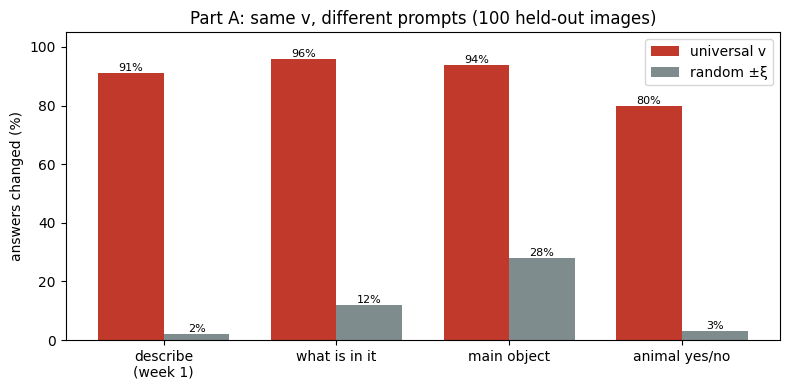

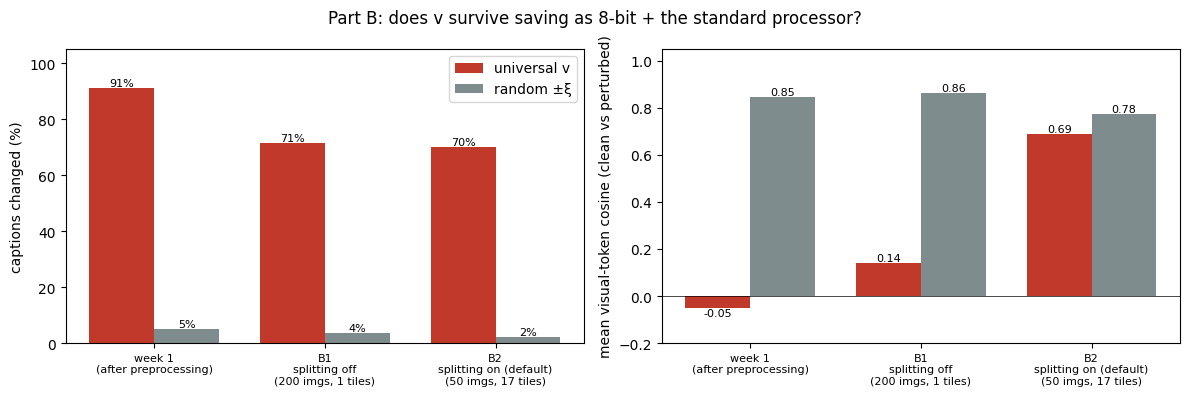

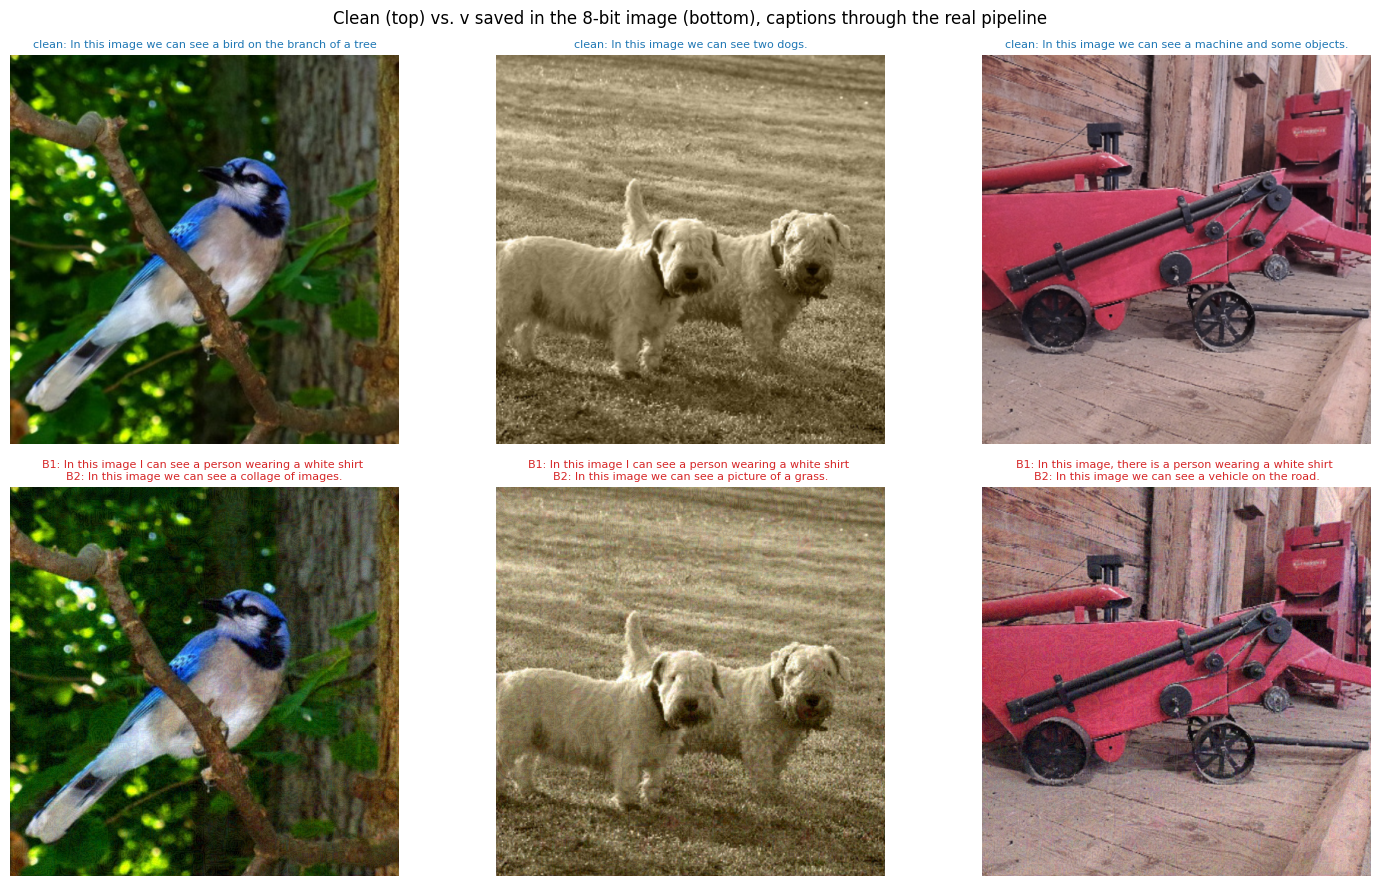

In [8]:
import json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
try:
    OUT
except NameError:
    from google.colab import drive; drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/uap_smolvlm")
D = json.load(open(OUT / "pipeline_prompts_results.json"))
R, EX = D["results"], D["examples"]
COL = {"universal v": "#c0392b", "random ±ξ": "#7f8c8d"}

# ---- Figure 1: prompt dependence ----
A = R["A_prompts"]; names = list(A)
fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(len(names)); w = 0.38
for k, cond in enumerate(["universal v", "random ±ξ"]):
    vals = [100 * (A[n][cond].get("changed", A[n][cond].get("answer_flipped"))) for n in names]
    b = ax.bar(x + (k - .5) * w, vals, w, label=cond, color=COL[cond])
    ax.bar_label(b, fmt="%.0f%%", fontsize=8)
ax.set_xticks(x, [n.replace(" (training)", "\n(training)") for n in names]); ax.set_ylim(0, 105)
ax.set_ylabel("answers changed (%)"); ax.set_title("Part A: same v, different prompts (100 held-out images)")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "prompt_dependence.png", dpi=150); plt.show()

# ---- Figure 2: real pipeline ----
B = R["B_pipeline"]
rows = {"training path\n(after preprocessing)": {"universal v": (0.910, -0.051), "random ±ξ": (0.050, 0.846)}}
for label, r in B.items():
    rows[label.replace(" splitting", "\nsplitting") + f"\n({r['n_images']} imgs, {r['tiles_per_image']} tiles)"] = \
        {c: (r[c]["changed"], r[c]["token_cos"]) for c in ["universal v", "random ±ξ"]}
labels = list(rows); x = np.arange(len(labels))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for j, (metric, ylab) in enumerate([(0, "captions changed (%)"), (1, "mean visual-token cosine (clean vs perturbed)")]):
    for k, cond in enumerate(["universal v", "random ±ξ"]):
        vals = [rows[l][cond][metric] * (100 if metric == 0 else 1) for l in labels]
        b = axs[j].bar(x + (k - .5) * w, vals, w, label=cond, color=COL[cond])
        axs[j].bar_label(b, fmt="%.0f%%" if metric == 0 else "%.2f", fontsize=8)
    axs[j].set_xticks(x, labels, fontsize=8); axs[j].set_ylabel(ylab); axs[j].axhline(0, color="k", lw=.5)
axs[0].set_ylim(0, 105); axs[1].set_ylim(-0.2, 1.05); axs[0].legend()
plt.suptitle("Part B: does v survive saving as 8-bit + the standard processor?"); plt.tight_layout()
plt.savefig(OUT / "real_pipeline.png", dpi=150); plt.show()

# ---- Figure 3: images with their captions (needs this session's variables) ----
try:
    fig, ax = plt.subplots(2, 3, figsize=(15, 9))
    b1, b2 = EX["B|B1 splitting off|universal v"], EX["B|B2 splitting on (default)|universal v"]
    for j in range(3):
        ax[0, j].imshow(E_u8[j].permute(1, 2, 0).numpy())
        ax[0, j].set_title("clean: " + b1[j][0][:55], fontsize=8, color="tab:blue")
        ax[1, j].imshow(np.asarray(to_pil_u8(E_u8[j], v)))
        ax[1, j].set_title("B1: " + b1[j][1][:55] + "\nB2: " + b2[j][1][:55], fontsize=8, color="tab:red")
        ax[0, j].axis("off"); ax[1, j].axis("off")
    plt.suptitle("Clean (top) vs. v saved in the 8-bit image (bottom), captions through the real pipeline")
    plt.tight_layout(); plt.savefig(OUT / "real_pipeline_examples.png", dpi=150); plt.show()
except (NameError, KeyError):
    plt.close(); print("Image panel skipped: E_u8 / v not in memory (charts above are complete).")